In [1]:
from utils.evaluation_utils import *
from utils.metrics_utils import *
from IPython.display import display

## Beispiel-Bild
- Regensburg DEZ-Kreuzung
- von Mapillary
- selbst annotiert

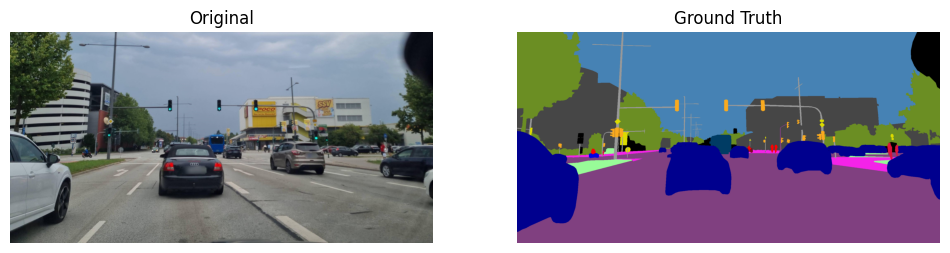

In [2]:
cvat_ctx = load_demo_context(image_name="bild6r.jpg", label_name="bild6.png")
image = cvat_ctx["image"]
rgb_label = cvat_ctx["label"]

plot_images(image, "Original", rgb_label, "Ground Truth")

classes = cvat_ctx["classes"]
color_to_class = cvat_ctx["color_to_class"]
image_key = cvat_ctx["image_key"]

def show_instance_metrics(rgb_mask):
    report = make_instance_report(
        rgb_mask,
        image_key,
        classes,
        color_to_class,
        manual_metrics=MANUAL_METRICS,
        instance_methods=INSTANCE_METHODS,
    )
    print("Summary: ")
    display(report["summary"])
    print("Computed metrics (per class):")
    display(report["computed_instances"])
    print("Manual metrics (per class):")
    display(report["manual_instances"])
    print("Comparison (computed - manual):")
    display(report["instance_comparison"])


## Segmentierung

Loaded model: deeplabv3plus
Best checkpoint:
 - Epoch: 122.000
 - Train Loss: 0.027
 - Train Accuracy: 0.971
 - Train MIoU: 0.810
 - Val Loss: 0.081
 - Val Accuracy: 0.952
 - Val MIoU: 0.634


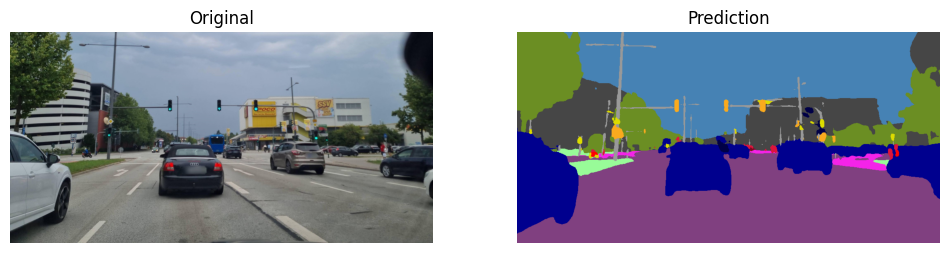

Results:
 - MIoU: 0.47024882558014536
 - Pixel Accuracy: 0.9519867300987244
Summary: 


,width,height,entropy,num_present_classes
image,,,,
bild6.png,1024,512,1.70313,14


Computed metrics (per class):


,method,pixel_share,pixel_count,computed_instances
class,,,,
background,cc,0.000000,0,0
bicycle,peaks,0.000143,75,1
building,cc,0.118891,62333,27
bus,watershed,0.000000,0,0
car,watershed,0.131639,69017,4
guard rail,cc,0.000000,0,0
motorcycle,peaks,0.000000,0,0
parking,cc,0.000000,0,0
person,watershed,0.001896,994,0


Manual metrics (per class):


,manual_instances
class,
background,0
road,0
sidewalk,0
parking,0
rail track,0
building,0
guard rail,0
pole,0
traffic light,0


Comparison (computed - manual):


,method,computed_instances,manual_instances,diff,abs_diff
class,,,,,
background,cc,0,0,0,0
bicycle,peaks,1,1,0,0
building,cc,27,0,27,27
bus,watershed,0,0,0,0
car,watershed,4,7,-3,3
guard rail,cc,0,0,0,0
motorcycle,peaks,0,0,0,0
parking,cc,0,0,0,0
person,watershed,0,3,-3,3


In [3]:
model, device, _ = load_model("deeplab", "deeplab_cityscapes_giga_run_3271161")
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")

show_instance_metrics(rgb_pred)


In [ ]:
#TODO
model, device, _ = load_model("segformer", "segformer_cityscapes_giga_run_") ###
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")

show_instance_metrics(rgb_pred)


In [ ]:
#TODO
model, device, _ = load_model("unet", "unet_cityscapes_giga_run_") ###
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")

show_instance_metrics(rgb_pred)
